# 08.06 — Brick 6: Bridging Story Positions

This notebook is **only Brick 6**.

It does not explain NLP embeddings.  
It does not rebuild the network.  
It does not relabel all communities.  
It does not focus on central/typical films. That was Brick 5.

Its job is to answer one reader question:

> What does it mean for a film to bridge different narrative neighborhoods?

## Thesis-level idea

A bridging film is **not** automatically:

```text
the most famous film
the highest-rated film
the highest-revenue film
the “best” film
```

A bridging film means:

```text
a film that sits between different story regions in the plot-similarity network
```

So this brick explains betweenness centrality as **narrative brokerage / cross-community story position**.

## Figures produced

```text
outputs/thesis_bricks/06_bridging_story_positions/figures/
```

1. `01_bridging_as_narrative_brokerage.png`  
2. `02_betweenness_explainer.png`  
3. `03_betweenness_distribution.png`  
4. `04_bridging_films_ranked_table.png`  
5. `05_bridge_profile_CXX.png` for selected bridging films  
6. `06_bridge_local_cross_community_neighborhood_CXX.png` for selected films  
7. `07_bridge_vs_centrality_selected_map.png`  
8. `08_bridging_interpretation_summary.png`  

## Design rule

Do not show thousands of points.

Use selected bridging examples, local cross-community neighborhoods, and clear interpretation graphics.


## 0. Setup

In [1]:

import os, re, math, textwrap, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)
pd.set_option("display.max_colwidth", 240)

COL = {
    "ink": "#222222",
    "muted": "#62666D",
    "grid": "#E4E7EB",
    "panel": "#F7F8FA",
    "blue": "#2F6FB3",
    "orange": "#D06C45",
    "green": "#2F8F5B",
    "purple": "#7A5BC2",
    "red": "#C94C4C",
    "yellow": "#D9A21B",
    "light_blue": "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green": "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray": "#F2F4F7",
    "white": "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7", "#F28E2B", "#59A14F", "#E15759", "#76B7B2", "#9C755F",
    "#EDC948", "#B07AA1", "#FF9DA7", "#BAB0AC", "#2F6FB3", "#D06C45",
    "#2F8F5B", "#7A5BC2", "#C94C4C", "#D9A21B", "#5C6BC0", "#26A69A",
    "#AB47BC", "#8D6E63", "#78909C", "#EC407A", "#43A047", "#FB8C00",
    "#6D4C41", "#00ACC1"
]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COL["ink"],
    "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink"],
    "ytick.color": COL["ink"],
    "text.color": COL["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": 320,
    "figure.dpi": 130,
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print("Saved:", path)
    return path

def wrap_text(s, width=42):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="...")

def clean_title(x):
    if pd.isna(x):
        return ""
    return str(x).replace("\n", " ").strip()

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def community_color(cid):
    try:
        return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception:
        return COL["blue"]

def safe_read(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print("Missing:", path)
    return None

def fmt_int(x):
    try:
        return f"{int(round(float(x))):,}"
    except Exception:
        return "—"

def fmt_float(x, d=3):
    try:
        return f"{float(x):.{d}f}"
    except Exception:
        return "—"

def detect_edge_cols(df):
    pairs = [("source", "target"), ("source_id", "target_id"), ("src", "dst"), ("u", "v"), ("node1", "node2"), ("from", "to")]
    for a, b in pairs:
        if a in df.columns and b in df.columns:
            return a, b
    return df.columns[0], df.columns[1]

def detect_weight_col(df):
    candidates = []
    for c in df.columns:
        cl = c.lower()
        if any(k in cl for k in ["weight", "similarity", "cosine", "score"]):
            candidates.append(c)
    return candidates[0] if candidates else None

def first_existing_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


## 1. Project paths

In [2]:

try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "06_bridging_story_positions"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:", FINAL_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions


## 2. Load files

In [3]:

FILES = {
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges": PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "bridging_visible": OUTPUT_TABLES_DIR / "top_betweenness_visible_franchise_capped.csv",
    "bridging_basic": OUTPUT_TABLES_DIR / "bridging_films_betweenness.csv",
    "top_visible_central": OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "top_weighted_degree_visible": OUTPUT_TABLES_DIR / "top_weighted_degree_visible_franchise_capped.csv",
}

for k, p in FILES.items():
    print(f"{k:28s}", p.exists(), "-", p)

nodes = safe_read(FILES["nodes"])
edges = safe_read(FILES["edges"])
community_labels = safe_read(FILES["community_labels"])
bridging_visible = safe_read(FILES["bridging_visible"])
bridging_basic = safe_read(FILES["bridging_basic"])
top_visible_central = safe_read(FILES["top_visible_central"])
top_weighted_degree_visible = safe_read(FILES["top_weighted_degree_visible"])

if nodes is None or edges is None:
    raise FileNotFoundError("This brick needs semantic_network_nodes_lcc.csv and semantic_network_edges_mutual_knn.csv.")

source_col, target_col = detect_edge_cols(edges)
weight_col = detect_weight_col(edges)

node_id_col = None
for c in ["tmdb_id", "id", "node_id", "movie_id", "imdb_id"]:
    if c in nodes.columns:
        node_id_col = c
        break
if node_id_col is None:
    node_id_col = nodes.columns[0]

title_col = "title" if "title" in nodes.columns else nodes.columns[0]

# Add labels to all relevant frames
if community_labels is not None:
    label_col = "suggested_label_manual" if "suggested_label_manual" in community_labels.columns else "narrative_label"
    label_lookup = community_labels[["community_id", label_col]].drop_duplicates().rename(columns={label_col: "narrative_label"})
    if "narrative_label" not in nodes.columns and "community_id" in nodes.columns:
        nodes = nodes.merge(label_lookup, on="community_id", how="left")
else:
    label_col = None
    label_lookup = None

for name in ["bridging_visible", "bridging_basic", "top_visible_central", "top_weighted_degree_visible"]:
    df = globals()[name]
    if df is not None and label_lookup is not None and "community_id" in df.columns and "narrative_label" not in df.columns:
        globals()[name] = df.merge(label_lookup, on="community_id", how="left")

print()
print("nodes:", nodes.shape)
print("edges:", edges.shape)
print("source_col:", source_col)
print("target_col:", target_col)
print("weight_col:", weight_col)
print("node_id_col:", node_id_col)
print("title_col:", title_col)


nodes                        True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
edges                        True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_edges_mutual_knn.csv
community_labels             True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
bridging_visible             True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_betweenness_visible_franchise_capped.csv
bridging_basic               True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/bridging_films_betweenness.csv
top_visible_central          True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_visible_central_films_per_community.csv
top_weighted_degree_visible  True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_weighted_degree_visible_franchise_capped.csv

nodes: (19202, 31)
edges: (86685, 9)
source

## 3. Build bridging diagnostics and lookup tables

In [4]:

# Prepare edge table.
edge_tmp = edges[[source_col, target_col] + ([weight_col] if weight_col else [])].copy()
edge_tmp = edge_tmp.rename(columns={source_col: "source_id", target_col: "target_id"})
if weight_col:
    edge_tmp = edge_tmp.rename(columns={weight_col: "edge_weight"})
else:
    edge_tmp["edge_weight"] = 1.0

# Compute degree and weighted degree from edges as fallback.
degree_source = edge_tmp.groupby("source_id").size()
degree_target = edge_tmp.groupby("target_id").size()
degree = degree_source.add(degree_target, fill_value=0).rename("degree_from_edges").reset_index().rename(columns={"index": node_id_col})

w_source = edge_tmp.groupby("source_id")["edge_weight"].sum()
w_target = edge_tmp.groupby("target_id")["edge_weight"].sum()
w_degree = w_source.add(w_target, fill_value=0).rename("weighted_degree_from_edges").reset_index().rename(columns={"index": node_id_col})

bridge_nodes = nodes.merge(degree, on=node_id_col, how="left").merge(w_degree, on=node_id_col, how="left")
bridge_nodes["degree_from_edges"] = bridge_nodes["degree_from_edges"].fillna(0)
bridge_nodes["weighted_degree_from_edges"] = bridge_nodes["weighted_degree_from_edges"].fillna(0)

# Pick betweenness column.
bet_col = first_existing_col(bridge_nodes, ["betweenness_centrality_sampled", "betweenness", "betweenness_centrality"])
if bet_col is None:
    print("WARNING: No betweenness column found in nodes. Will rely on uploaded bridging tables if possible.")
else:
    bridge_nodes["bridge_score"] = bridge_nodes[bet_col]
    bridge_nodes["bridge_percentile"] = bridge_nodes["bridge_score"].rank(pct=True)

# Choose a bridging list.
bridge_source = None
for df in [bridging_visible, bridging_basic]:
    if df is not None and len(df):
        bridge_source = df.copy()
        break

if bridge_source is None and bet_col is not None:
    bridge_source = bridge_nodes.sort_values("bridge_score", ascending=False).copy()

if bridge_source is None:
    raise ValueError("No bridge source table and no betweenness column found.")

# Attach node IDs to bridge_source when missing.
node_lookup_by_title = nodes.copy()
node_lookup_by_title["_title_lower"] = node_lookup_by_title[title_col].astype(str).str.strip().str.lower()

def find_node_by_title(title):
    if not title:
        return None
    t = str(title).strip().lower()
    exact = node_lookup_by_title[node_lookup_by_title["_title_lower"] == t]
    if len(exact):
        return exact.iloc[0]
    contains = node_lookup_by_title[node_lookup_by_title["_title_lower"].str.contains(re.escape(t), na=False)]
    if len(contains):
        return contains.iloc[0]
    return None

if node_id_col not in bridge_source.columns:
    ids = []
    for _, r in bridge_source.iterrows():
        t = clean_title(r.get("title", ""))
        hit = find_node_by_title(t)
        ids.append(hit[node_id_col] if hit is not None else np.nan)
    bridge_source[node_id_col] = ids

bridge_source = bridge_source.dropna(subset=[node_id_col]).copy()

# Attach bridge and central scores from nodes.
merge_cols = [node_id_col, "degree_from_edges", "weighted_degree_from_edges"]
for c in ["weighted_degree", "pagerank", "bridge_score", "bridge_percentile", bet_col]:
    if c and c in bridge_nodes.columns and c not in merge_cols:
        merge_cols.append(c)

bridge_source = bridge_source.merge(
    bridge_nodes[merge_cols],
    on=node_id_col,
    how="left",
    suffixes=("", "_node")
)

# Normalize score columns.
if "bridge_score" not in bridge_source.columns:
    if bet_col and bet_col in bridge_source.columns:
        bridge_source["bridge_score"] = bridge_source[bet_col]
    elif f"{bet_col}_node" in bridge_source.columns:
        bridge_source["bridge_score"] = bridge_source[f"{bet_col}_node"]
    else:
        bc = first_existing_col(bridge_source, ["betweenness_centrality_sampled", "betweenness", "betweenness_centrality"])
        if bc:
            bridge_source["bridge_score"] = bridge_source[bc]
        else:
            bridge_source["bridge_score"] = np.nan

if "weighted_degree" in bridge_source.columns:
    bridge_source["typicality_score"] = bridge_source["weighted_degree"]
elif "weighted_degree_from_edges" in bridge_source.columns:
    bridge_source["typicality_score"] = bridge_source["weighted_degree_from_edges"]
else:
    bridge_source["typicality_score"] = np.nan

# Node lookup functions.
node_lookup = bridge_nodes.set_index(node_id_col, drop=False)

def film_title(node_id):
    if node_id in node_lookup.index:
        return clean_title(node_lookup.loc[node_id].get(title_col, node_id))
    return str(node_id)

def film_year(node_id):
    if node_id in node_lookup.index and "release_year" in node_lookup.columns:
        v = node_lookup.loc[node_id].get("release_year")
        if pd.notna(v):
            try:
                return int(v)
            except Exception:
                return "—"
    return "—"

def film_community(node_id):
    if node_id in node_lookup.index and "community_id" in node_lookup.columns:
        try:
            return int(node_lookup.loc[node_id].get("community_id"))
        except Exception:
            return node_lookup.loc[node_id].get("community_id")
    return "—"

def film_label(node_id):
    if node_id in node_lookup.index and "narrative_label" in node_lookup.columns:
        return str(node_lookup.loc[node_id].get("narrative_label", ""))
    return ""

def get_neighbors(anchor_id, top_n=12):
    sub = edge_tmp[(edge_tmp["source_id"] == anchor_id) | (edge_tmp["target_id"] == anchor_id)].copy()
    if sub.empty:
        return pd.DataFrame()
    sub["neighbor_id"] = np.where(sub["source_id"] == anchor_id, sub["target_id"], sub["source_id"])
    sub = sub.sort_values("edge_weight", ascending=False).head(top_n)
    rows = []
    for _, r in sub.iterrows():
        nid = r["neighbor_id"]
        if nid in node_lookup.index:
            nrow = node_lookup.loc[nid]
            rows.append({
                "anchor_id": anchor_id,
                "neighbor_id": nid,
                "neighbor_title": film_title(nid),
                "neighbor_year": film_year(nid),
                "neighbor_community": film_community(nid),
                "neighbor_label": film_label(nid),
                "edge_weight": r["edge_weight"],
                "neighbor_degree": nrow.get("degree_from_edges", np.nan),
                "neighbor_weighted_degree": nrow.get("weighted_degree_from_edges", np.nan),
                "neighbor_betweenness": nrow.get("bridge_score", np.nan) if "bridge_score" in nrow.index else np.nan,
            })
    return pd.DataFrame(rows)

save_table(bridge_nodes, "00_bridge_node_diagnostics.csv")
save_table(bridge_source, "00_bridge_source_for_figures.csv")

display(bridge_source.head())


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/tables/00_bridge_node_diagnostics.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/tables/00_bridge_source_for_figures.csv


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient,narrative_label,tmdb_id,degree_from_edges,weighted_degree_from_edges,weighted_degree_node,pagerank_node,bridge_score,bridge_percentile,betweenness_centrality_sampled_node,typicality_score
0,The Bandit,1996,Crime,355.0,7.3,22,18,9.672851,0.000093,0.002223,0.000004,0.003452,"Relationship drama, romantic comedy, and emotional-family crossover",26900,0.0,0.000000,9.672851,0.000093,0.002223,1.000000,0.002223,9.672851
1,The TV Set,2007,Comedy,89.0,6.0,6,13,6.224862,0.000077,0.002018,0.000002,0.104251,"Identity crisis, family/home disruption, and adult-life thriller-comedy",17320,13.0,7.286748,6.224862,0.000077,0.002018,0.999948,0.002018,6.224862
2,Ace Ventura: When Nature Calls,1995,Crime,4524.0,6.3,10,14,6.649705,0.000078,0.001957,0.000001,0.016134,"Adventure spectacle, creature threat, and family-animation peril",9273,10.0,4.942719,6.649705,0.000078,0.001957,0.999896,0.001957,6.649705
3,Intacto,2001,Action,196.0,6.6,23,18,9.807808,0.000094,0.001868,0.000007,0.021826,"Crime, heist, revenge, and underworld action",10856,8.0,4.295545,9.807808,0.000094,0.001868,0.999792,0.001868,9.807808
4,The Perfect Weapon,1991,Action,124.0,6.2,10,16,8.534136,0.000098,0.001788,0.000004,0.018160,"Adventure spectacle, creature threat, and family-animation peril",34421,0.0,0.000000,8.534136,0.000098,0.001788,0.999740,0.001788,8.534136


## 4. Figure 1 — Bridging as narrative brokerage

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/01_bridging_as_narrative_brokerage.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/01_bridging_as_narrative_brokerage.svg


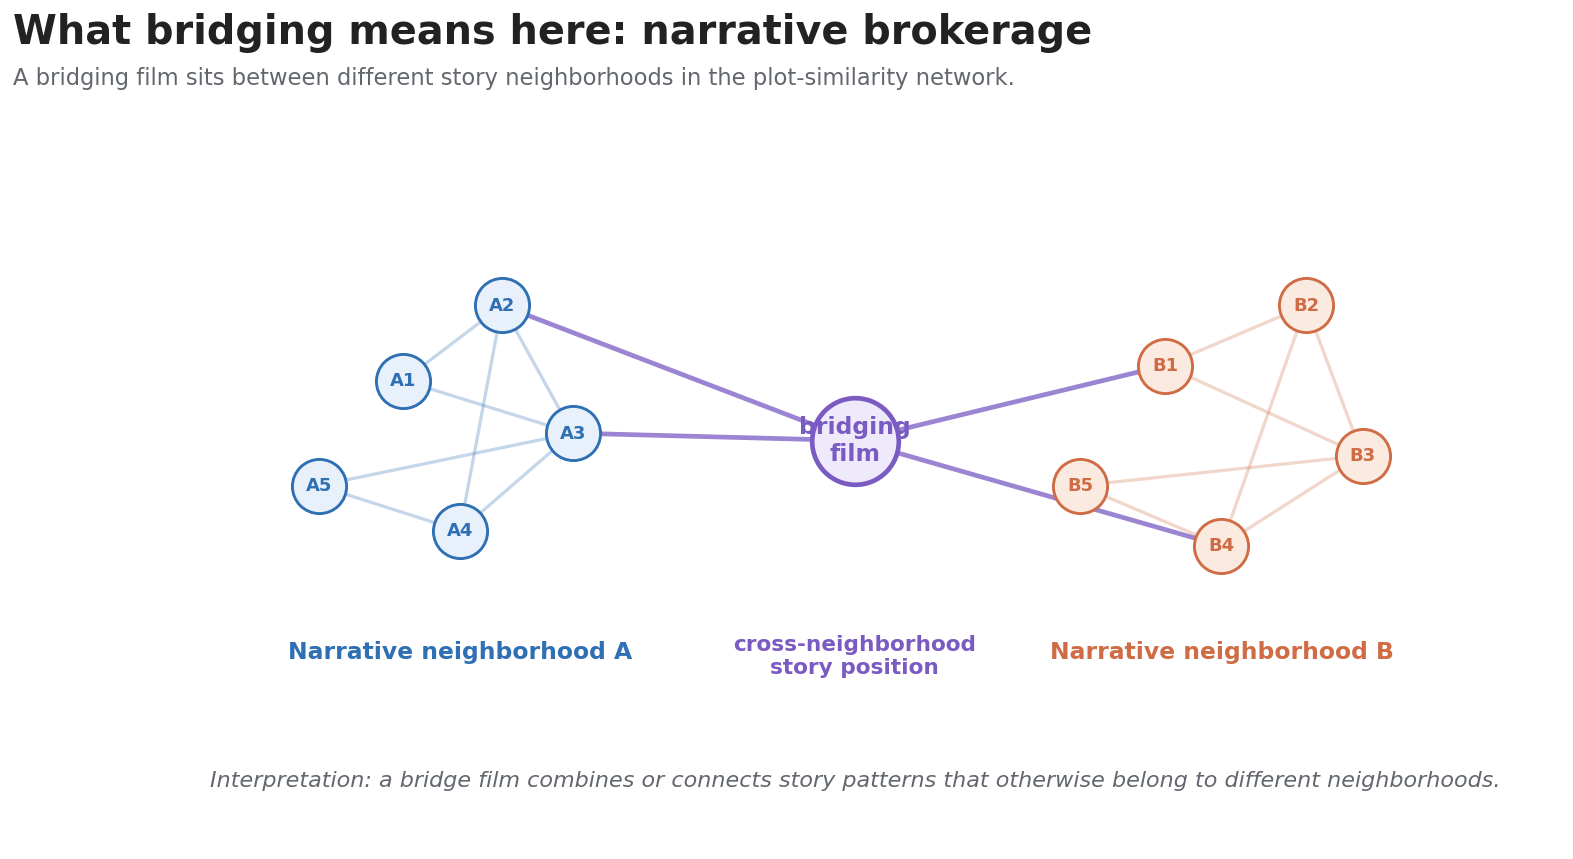

In [5]:

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "What bridging means here: narrative brokerage",
    "A bridging film sits between different story neighborhoods in the plot-similarity network."
)

# Two communities and one bridge node.
left_nodes = [(0.18, 0.62), (0.25, 0.72), (0.30, 0.55), (0.22, 0.42), (0.12, 0.48)]
right_nodes = [(0.72, 0.64), (0.82, 0.72), (0.86, 0.52), (0.76, 0.40), (0.66, 0.48)]
bridge = (0.50, 0.54)

# Internal links
for group, color in [(left_nodes, COL["blue"]), (right_nodes, COL["orange"])]:
    for i, (x1, y1) in enumerate(group):
        for j, (x2, y2) in enumerate(group):
            if i < j and abs(i-j) <= 2:
                ax.plot([x1, x2], [y1, y2], color=color, lw=1.8, alpha=0.28, zorder=1)

# Bridge links
for x, y in [left_nodes[1], left_nodes[2], right_nodes[0], right_nodes[3]]:
    ax.plot([bridge[0], x], [bridge[1], y], color=COL["purple"], lw=2.6, alpha=0.75, zorder=2)

# Nodes
for i, (x, y) in enumerate(left_nodes):
    ax.scatter(x, y, s=900, color=COL["light_blue"], edgecolor=COL["blue"], linewidth=1.6, zorder=3)
    ax.text(x, y, f"A{i+1}", ha="center", va="center", fontsize=10, fontweight="bold", color=COL["blue"], zorder=4)

for i, (x, y) in enumerate(right_nodes):
    ax.scatter(x, y, s=900, color=COL["light_orange"], edgecolor=COL["orange"], linewidth=1.6, zorder=3)
    ax.text(x, y, f"B{i+1}", ha="center", va="center", fontsize=10, fontweight="bold", color=COL["orange"], zorder=4)

ax.scatter(bridge[0], bridge[1], s=2300, color=COL["light_purple"], edgecolor=COL["purple"], linewidth=2.6, zorder=5)
ax.text(bridge[0], bridge[1], "bridging\nfilm", ha="center", va="center", fontsize=13, fontweight="bold", color=COL["purple"], zorder=6)

# Labels
ax.text(0.22, 0.25, "Narrative neighborhood A", ha="center", fontsize=13, fontweight="bold", color=COL["blue"])
ax.text(0.76, 0.25, "Narrative neighborhood B", ha="center", fontsize=13, fontweight="bold", color=COL["orange"])
ax.text(0.50, 0.23, "cross-neighborhood\nstory position", ha="center", fontsize=12, fontweight="bold", color=COL["purple"])

ax.text(
    0.5, 0.08,
    "Interpretation: a bridge film combines or connects story patterns that otherwise belong to different neighborhoods.",
    ha="center",
    fontsize=12.3,
    color=COL["muted"],
    style="italic"
)

save_fig(fig, "01_bridging_as_narrative_brokerage.png")
plt.show()


## 5. Figure 2 — Betweenness explainer

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/02_betweenness_explainer.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/02_betweenness_explainer.svg


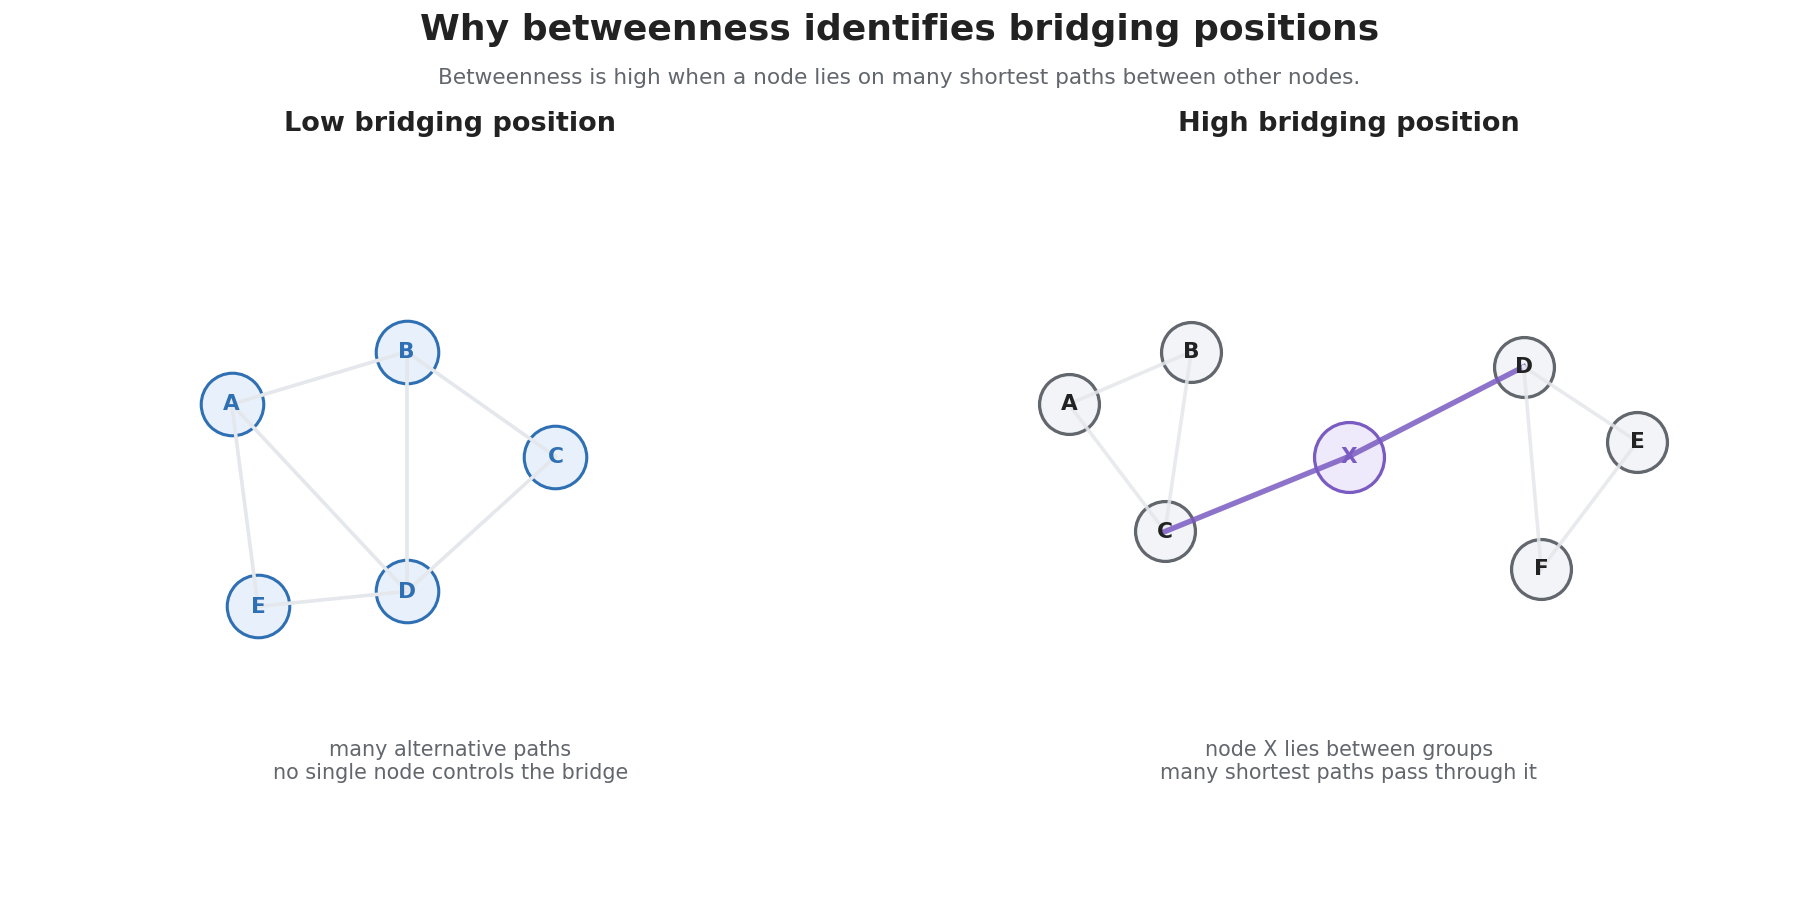

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6.8))
fig.suptitle("Why betweenness identifies bridging positions", fontsize=20, fontweight="bold", y=1.02)
fig.text(
    0.5, 0.94,
    "Betweenness is high when a node lies on many shortest paths between other nodes.",
    ha="center",
    fontsize=12,
    color=COL["muted"]
)

# Left: no bridge / many paths internal
ax = axes[0]
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Low bridging position", fontsize=15, fontweight="bold")

pos1 = {
    "A": (0.25, 0.65), "B": (0.45, 0.72), "C": (0.62, 0.58), "D": (0.45, 0.40), "E": (0.28, 0.38)
}
edges1 = [("A","B"),("B","C"),("C","D"),("D","E"),("E","A"),("A","D"),("B","D")]
for u, v in edges1:
    ax.plot([pos1[u][0], pos1[v][0]], [pos1[u][1], pos1[v][1]], color=COL["grid"], lw=2)
for k, (x, y) in pos1.items():
    ax.scatter(x, y, s=1200, color=COL["light_blue"], edgecolor=COL["blue"], lw=1.7)
    ax.text(x, y, k, ha="center", va="center", fontsize=12, fontweight="bold", color=COL["blue"])
ax.text(0.5, 0.15, "many alternative paths\nno single node controls the bridge", ha="center", fontsize=11.5, color=COL["muted"])

# Right: one bridge connecting groups
ax = axes[1]
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("High bridging position", fontsize=15, fontweight="bold")

pos2 = {
    "A": (0.18, 0.65), "B": (0.32, 0.72), "C": (0.29, 0.48),
    "X": (0.50, 0.58),
    "D": (0.70, 0.70), "E": (0.83, 0.60), "F": (0.72, 0.43)
}
edges2 = [("A","B"),("A","C"),("B","C"),("C","X"),("X","D"),("D","E"),("D","F"),("E","F")]
for u, v in edges2:
    color = COL["purple"] if "X" in [u, v] else COL["grid"]
    lw = 3.0 if "X" in [u, v] else 2.0
    ax.plot([pos2[u][0], pos2[v][0]], [pos2[u][1], pos2[v][1]], color=color, lw=lw, alpha=0.85)
for k, (x, y) in pos2.items():
    if k == "X":
        face, edge, tcol = COL["light_purple"], COL["purple"], COL["purple"]
        size = 1500
    else:
        face, edge, tcol = COL["light_gray"], COL["muted"], COL["ink"]
        size = 1100
    ax.scatter(x, y, s=size, color=face, edgecolor=edge, lw=1.8)
    ax.text(x, y, k, ha="center", va="center", fontsize=12, fontweight="bold", color=tcol)
ax.text(0.5, 0.15, "node X lies between groups\nmany shortest paths pass through it", ha="center", fontsize=11.5, color=COL["muted"])

plt.tight_layout()
save_fig(fig, "02_betweenness_explainer.png")
plt.show()


## 6. Figure 3 — Betweenness distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/tables/03_betweenness_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/03_betweenness_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/03_betweenness_distribution.svg


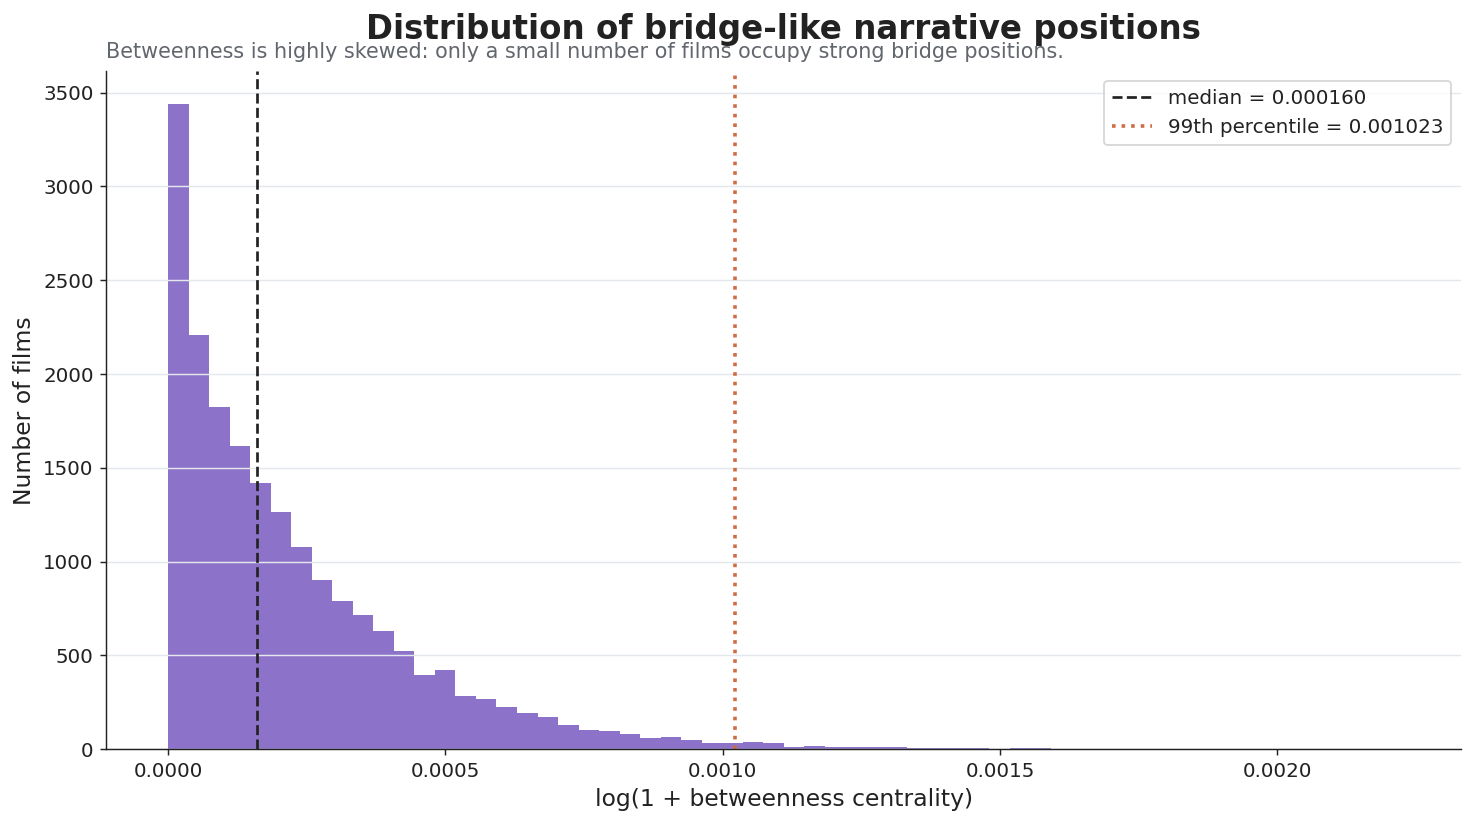

In [7]:

if "bridge_score" in bridge_nodes.columns:
    x = bridge_nodes["bridge_score"].dropna()
    x_log = np.log1p(x)

    summary = pd.DataFrame({
        "metric": ["n", "min", "median", "mean", "p75", "p90", "p95", "p99", "max"],
        "value": [len(x), x.min(), x.median(), x.mean(), x.quantile(.75), x.quantile(.90), x.quantile(.95), x.quantile(.99), x.max()]
    })
    save_table(summary, "03_betweenness_distribution_summary.csv")

    fig, ax = plt.subplots(figsize=(11.5, 6.5))
    ax.hist(x_log, bins=60, color=COL["purple"], alpha=0.86)
    ax.axvline(np.log1p(x.median()), color=COL["ink"], ls="--", lw=1.5, label=f"median = {x.median():.6f}")
    ax.axvline(np.log1p(x.quantile(.99)), color=COL["orange"], ls=":", lw=2.0, label=f"99th percentile = {x.quantile(.99):.6f}")

    ax.set_title("Distribution of bridge-like narrative positions", pad=18)
    ax.text(
        0, 1.02,
        "Betweenness is highly skewed: only a small number of films occupy strong bridge positions.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("log(1 + betweenness centrality)")
    ax.set_ylabel("Number of films")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])
    ax.legend()

    plt.tight_layout()
    save_fig(fig, "03_betweenness_distribution.png")
    plt.show()
else:
    print("No bridge_score column available.")


## 7. Figure 4 — Bridging films ranked table

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/tables/04_bridging_films_ranked_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/04_bridging_films_ranked_table.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/04_bridging_films_ranked_table.svg


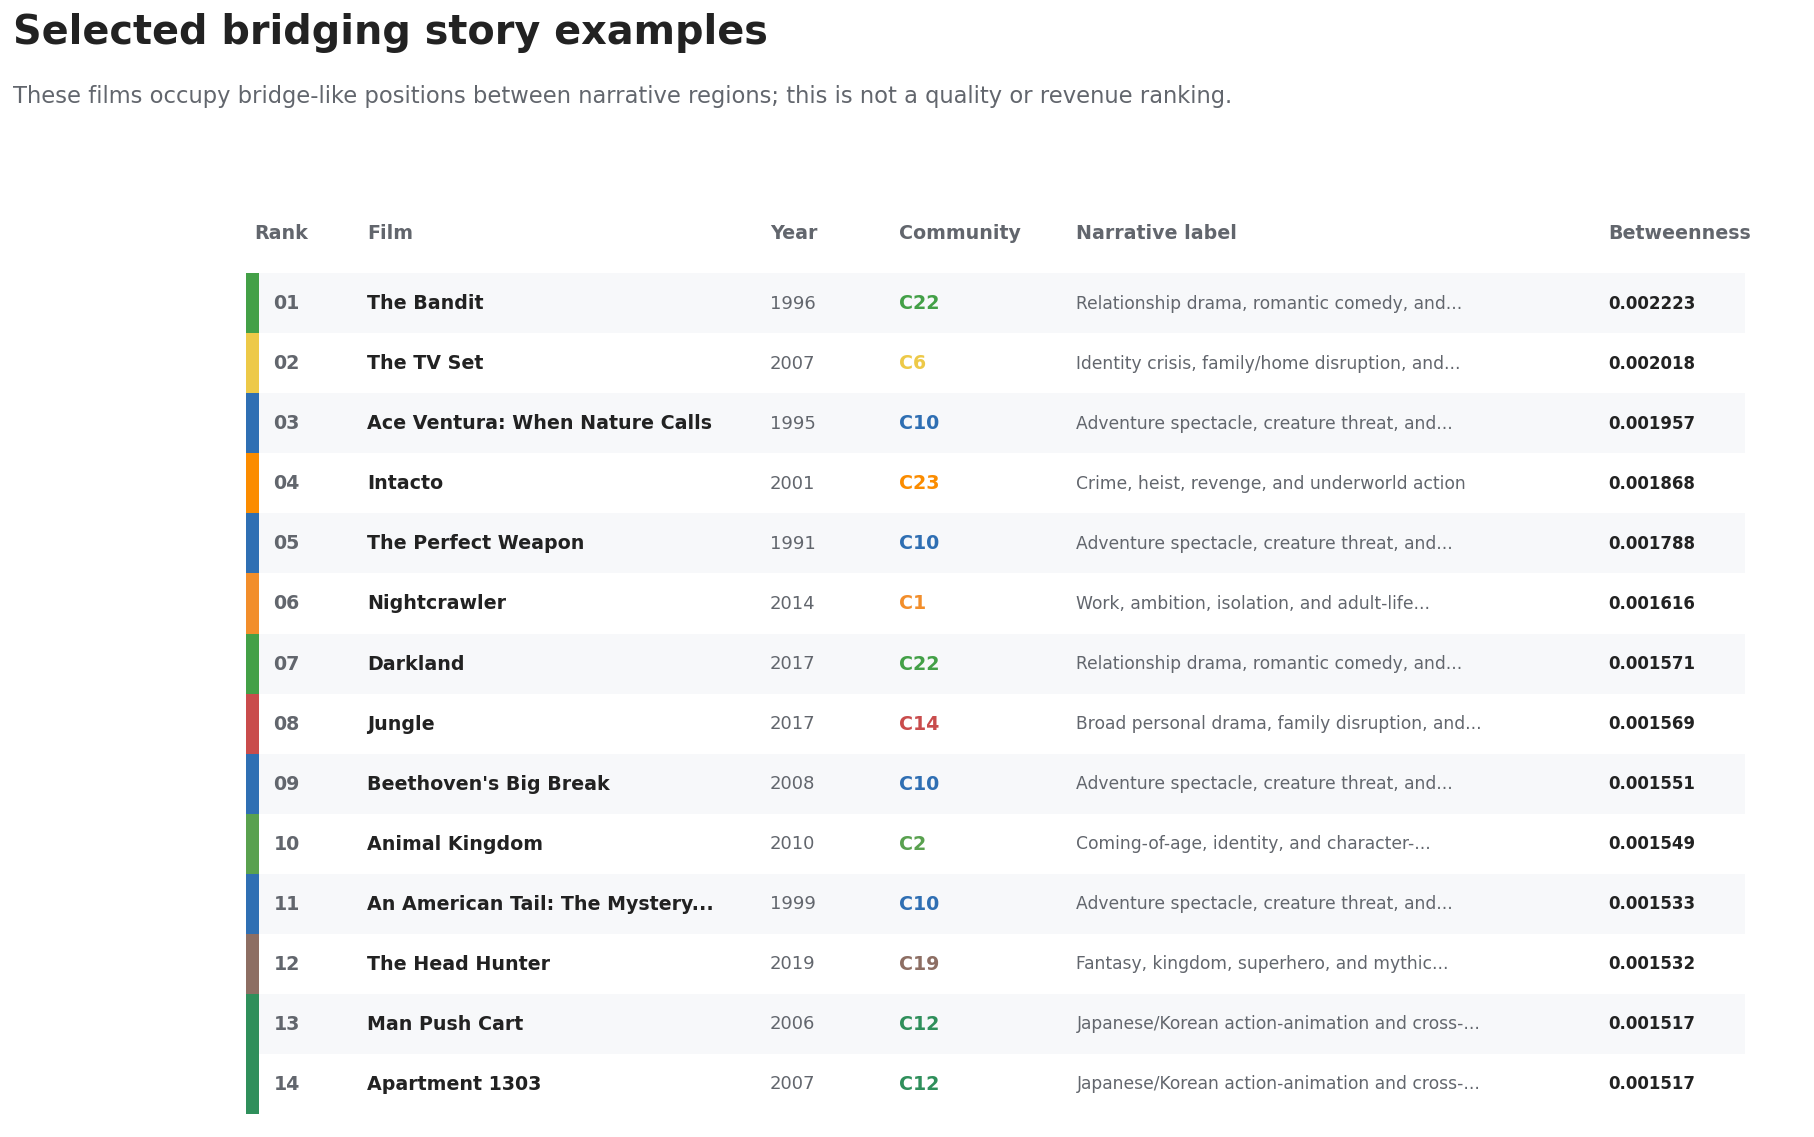

In [8]:

bridge_ranked = bridge_source.sort_values("bridge_score", ascending=False).head(14).copy()

save_table(bridge_ranked, "04_bridging_films_ranked_table.csv")

fig, ax = plt.subplots(figsize=(16, 10))
ax.axis("off")
title_block(
    fig,
    "Selected bridging story examples",
    "These films occupy bridge-like positions between narrative regions; this is not a quality or revenue ranking.",
    x=0.04,
    y=0.965
)

start_y = 0.84
row_h = 0.060
headers = ["Rank", "Film", "Year", "Community", "Narrative label", "Betweenness"]
xs = [0.04, 0.11, 0.36, 0.44, 0.55, 0.88]

for x0, h in zip(xs, headers):
    ax.text(x0, start_y + 0.045, h, transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=COL["muted"])

for i, (_, r) in enumerate(bridge_ranked.iterrows(), start=1):
    y = start_y - (i - 1) * row_h
    cid = int(r["community_id"]) if pd.notna(r.get("community_id")) else 0
    color = community_color(cid)
    bg = COL["panel"] if i % 2 == 1 else "white"
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.010), 0.93, row_h, transform=ax.transAxes, facecolor=bg, edgecolor="none"))
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.010), 0.008, row_h, transform=ax.transAxes, facecolor=color, edgecolor="none"))

    title = clean_title(r.get("title", r.get(title_col, "")))
    year = r.get("release_year", "")
    if pd.notna(year):
        try:
            year = int(year)
        except Exception:
            pass

    ax.text(0.052, y - 0.020, f"{i:02d}", transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=COL["muted"], va="center")
    ax.text(0.11, y - 0.020, shorten(title, 34), transform=ax.transAxes, fontsize=10.5, fontweight="bold", va="center")
    ax.text(0.36, y - 0.020, str(year), transform=ax.transAxes, fontsize=10.0, color=COL["muted"], va="center")
    ax.text(0.44, y - 0.020, f"C{cid}", transform=ax.transAxes, fontsize=10.5, fontweight="bold", color=color, va="center")
    ax.text(0.55, y - 0.020, shorten(r.get("narrative_label", ""), 47), transform=ax.transAxes, fontsize=9.5, color=COL["muted"], va="center")
    ax.text(0.88, y - 0.020, fmt_float(r.get("bridge_score", np.nan), 6), transform=ax.transAxes, fontsize=9.2, fontweight="bold", va="center")

save_fig(fig, "04_bridging_films_ranked_table.png")
plt.show()


## 8. Figure 5 — Bridge profile sheets

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C22_The_Bandit.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C22_The_Bandit.svg


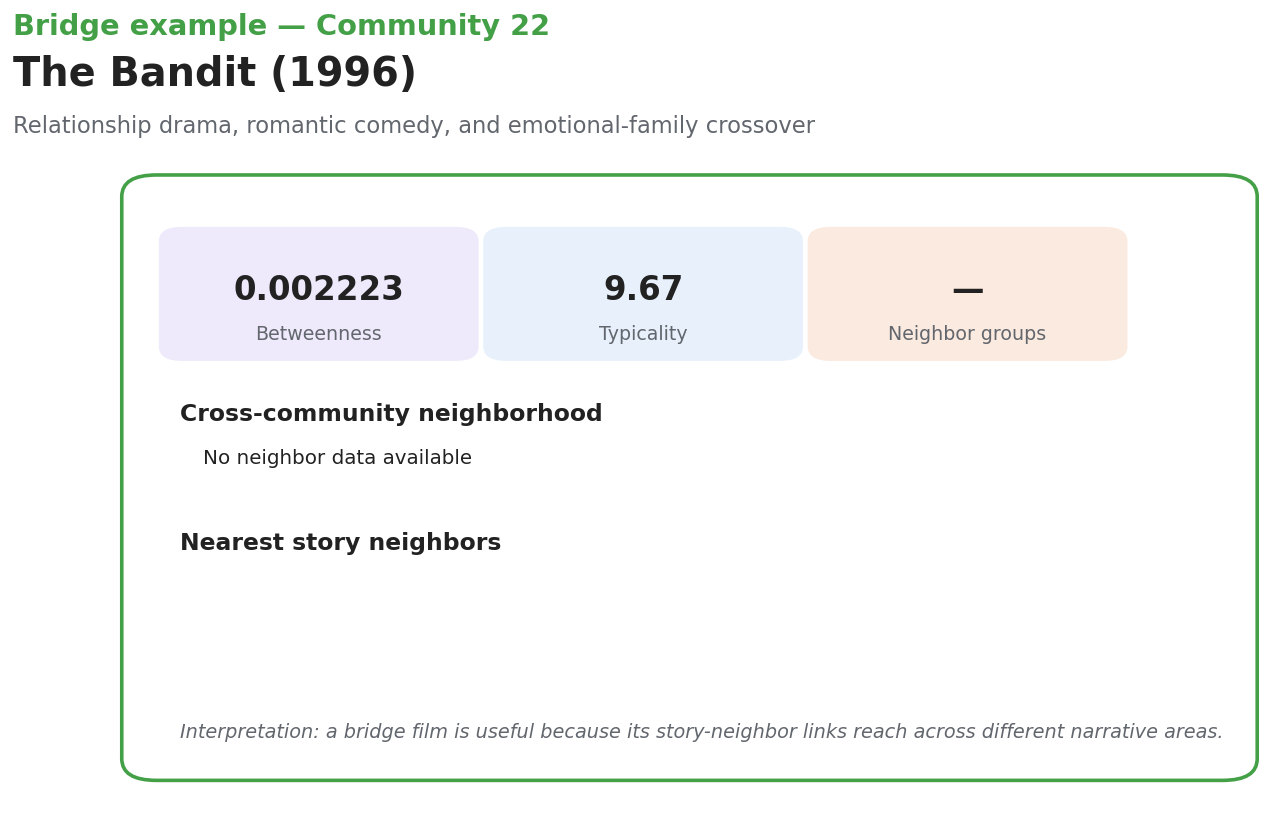

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C06_The_TV_Set.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C06_The_TV_Set.svg


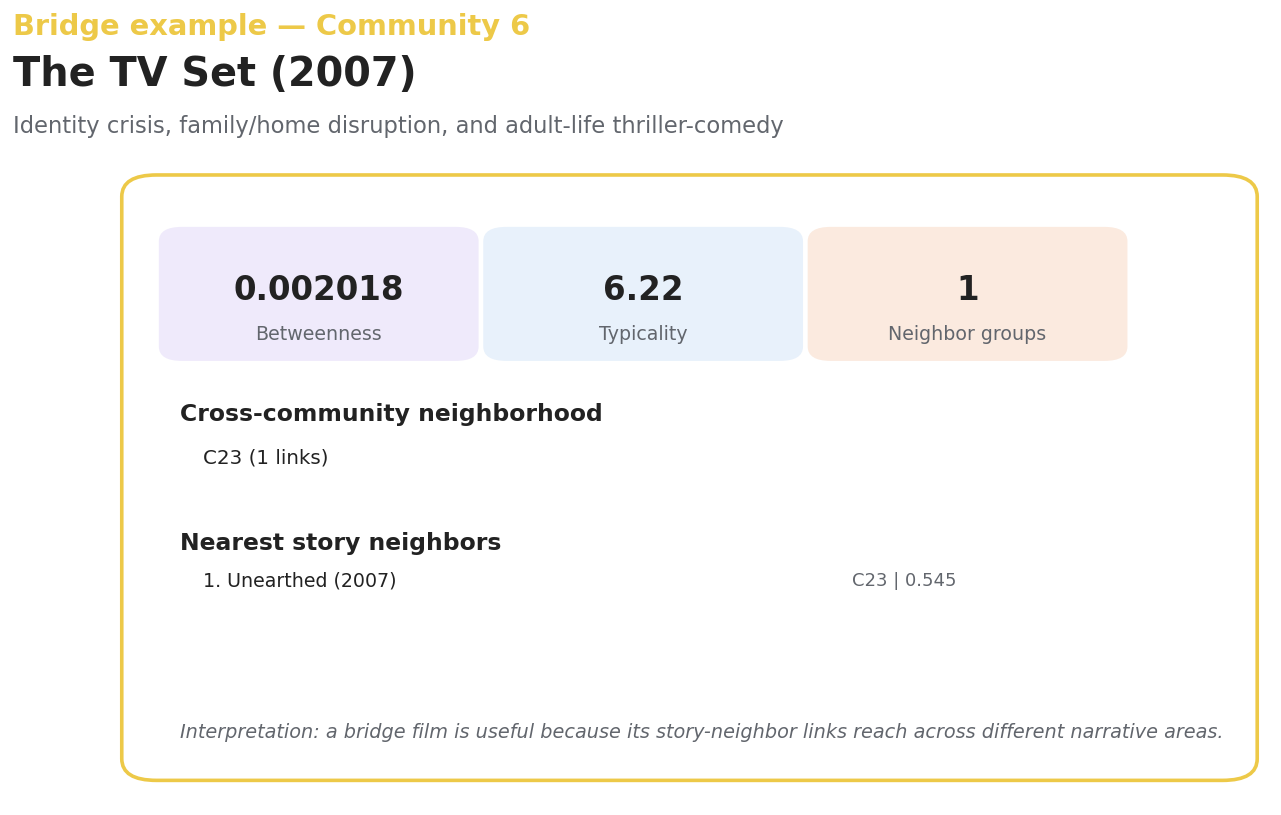

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C10_Ace_Ventura_When_Nature_C.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C10_Ace_Ventura_When_Nature_C.svg


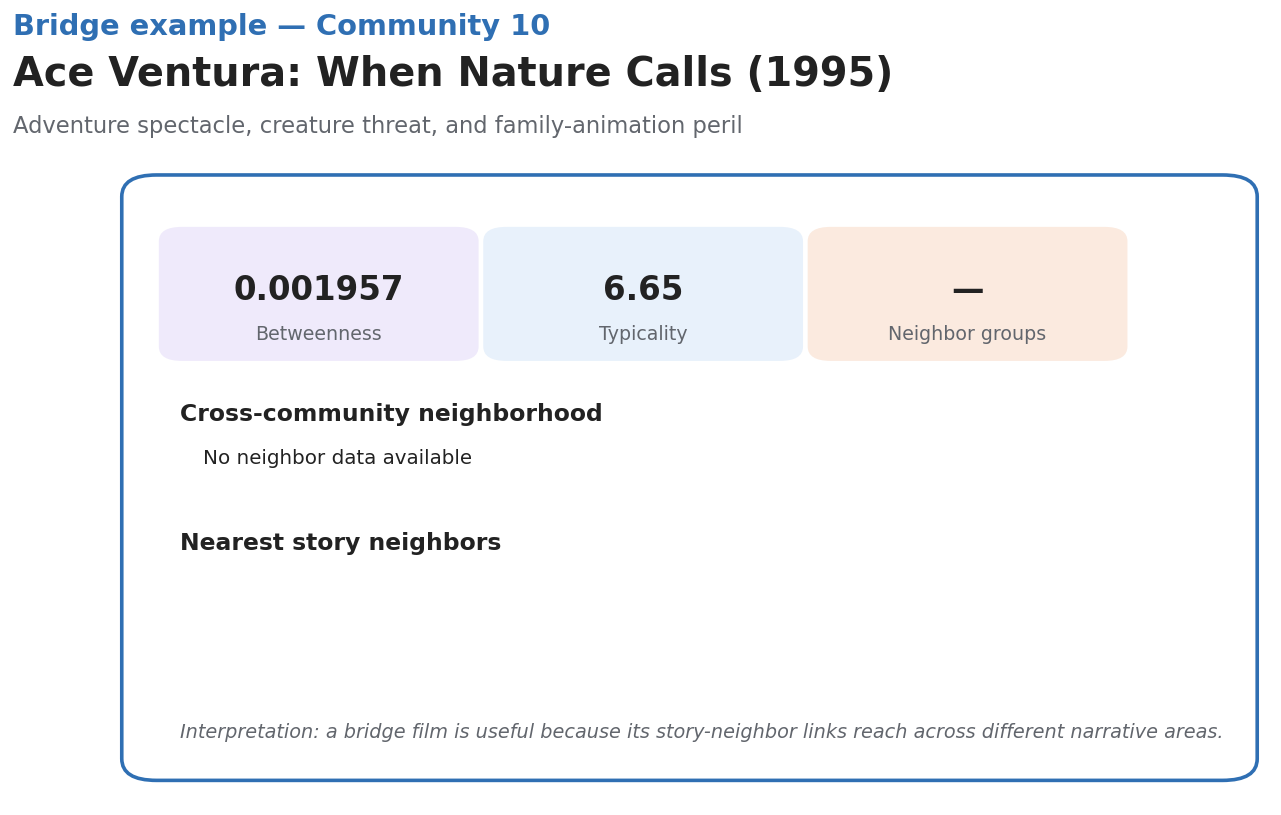

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C23_Intacto.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C23_Intacto.svg


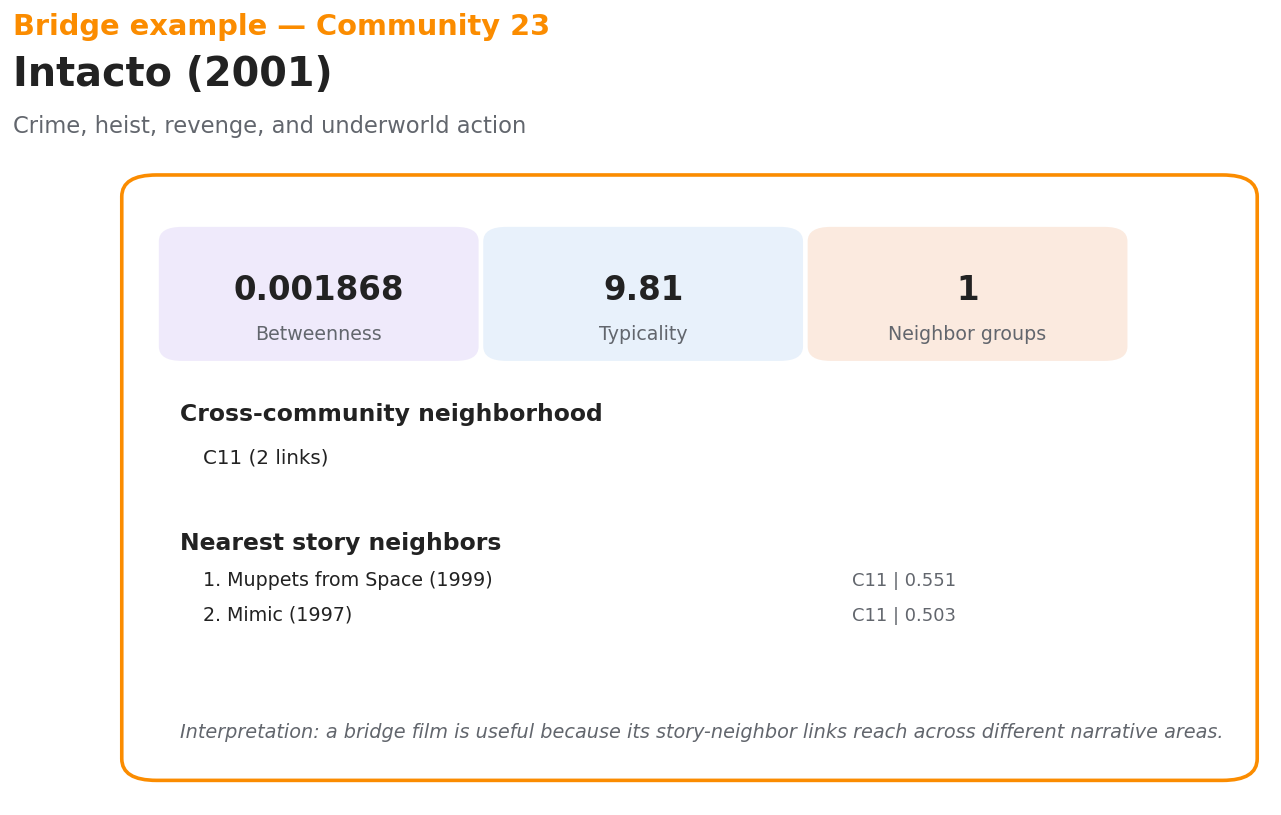

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C10_The_Perfect_Weapon.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C10_The_Perfect_Weapon.svg


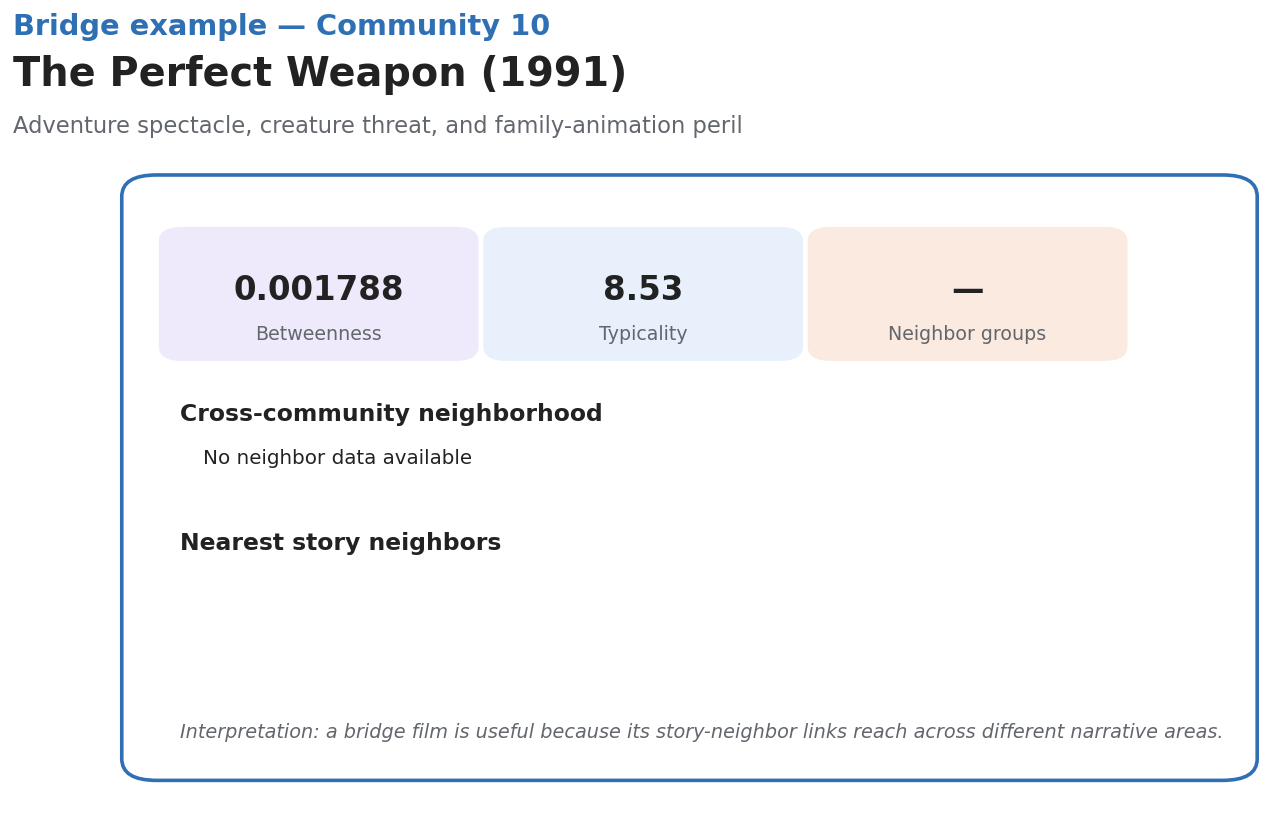

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C01_Nightcrawler.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/05_bridge_profile_C01_Nightcrawler.svg


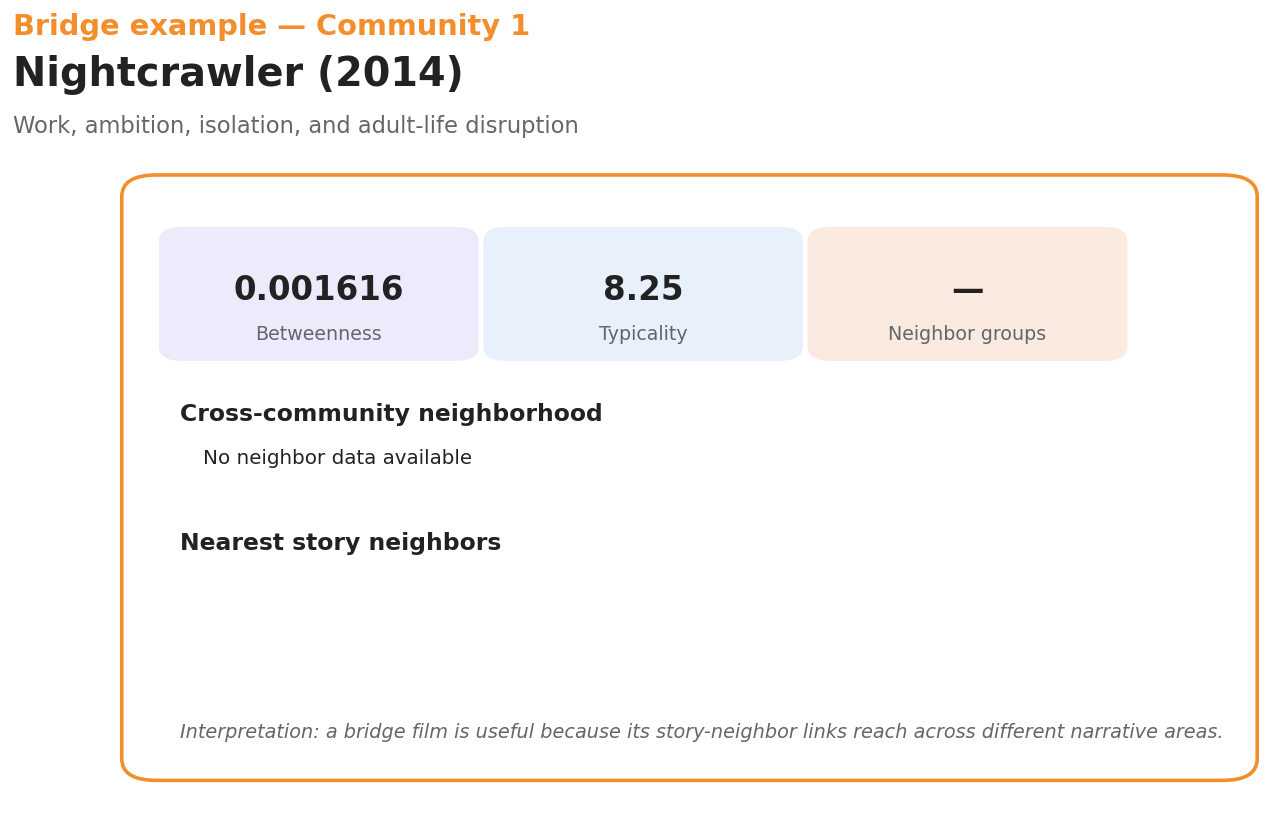

In [9]:

profiles = bridge_ranked.head(6).copy()

for _, r in profiles.iterrows():
    cid = int(r["community_id"]) if pd.notna(r.get("community_id")) else 0
    color = community_color(cid)
    node_id = r[node_id_col]
    title = clean_title(r.get("title", r.get(title_col, "")))
    year = r.get("release_year", "—")
    try:
        if pd.notna(year):
            year = int(year)
    except Exception:
        pass

    neigh = get_neighbors(node_id, top_n=10)
    label = str(r.get("narrative_label", ""))
    score = r.get("bridge_score", np.nan)
    typicality = r.get("typicality_score", np.nan)

    # Count neighbor communities.
    if len(neigh):
        comm_counts = neigh["neighbor_community"].value_counts().head(4)
        neighbor_comm_text = "; ".join([f"C{int(k)} ({int(v)} links)" for k, v in comm_counts.items()])
    else:
        neighbor_comm_text = "No neighbor data available"

    fig, ax = plt.subplots(figsize=(11.5, 7.2))
    ax.axis("off")

    fig.text(0.06, 0.93, f"Bridge example — Community {cid}", fontsize=16, fontweight="bold", color=color, ha="left")
    fig.text(0.06, 0.875, f"{title} ({year})", fontsize=22, fontweight="bold", color=COL["ink"], ha="left")
    fig.text(0.06, 0.825, wrap_text(label, 85), fontsize=12.5, color=COL["muted"], ha="left")

    # Cards
    card_data = [
        (0.06, "Betweenness", fmt_float(score, 6), COL["light_purple"]),
        (0.34, "Typicality", fmt_float(typicality, 2), COL["light_blue"]),
        (0.62, "Neighbor groups", str(neigh["neighbor_community"].nunique()) if len(neigh) else "—", COL["light_orange"]),
    ]
    for x0, label_c, value_c, bg in card_data:
        ax.add_patch(FancyBboxPatch(
            (x0, 0.63), 0.24, 0.15,
            boxstyle="round,pad=0.018,rounding_size=0.02",
            facecolor=bg,
            edgecolor="none",
            transform=ax.transAxes
        ))
        ax.text(x0 + 0.12, 0.71, value_c, transform=ax.transAxes, ha="center", va="center", fontsize=18, fontweight="bold")
        ax.text(x0 + 0.12, 0.65, label_c, transform=ax.transAxes, ha="center", va="center", fontsize=10.5, color=COL["muted"])

    # Neighbor communities
    ax.text(0.06, 0.53, "Cross-community neighborhood", transform=ax.transAxes, fontsize=13, fontweight="bold")
    ax.text(0.08, 0.47, wrap_text(neighbor_comm_text, 80), transform=ax.transAxes, fontsize=11.0, color=COL["ink"])

    # Top neighbors
    ax.text(0.06, 0.35, "Nearest story neighbors", transform=ax.transAxes, fontsize=13, fontweight="bold")
    y = 0.30
    if len(neigh):
        for i, (_, nr) in enumerate(neigh.head(4).iterrows(), start=1):
            sim = nr.get("edge_weight", np.nan)
            sim_txt = f"{sim:.3f}" if pd.notna(sim) else "edge"
            ax.text(0.08, y, f"{i}. {shorten(nr['neighbor_title'], 55)} ({nr['neighbor_year']})", transform=ax.transAxes, fontsize=10.5, color=COL["ink"])
            ax.text(0.64, y, f"C{nr['neighbor_community']} | {sim_txt}", transform=ax.transAxes, fontsize=10.0, color=COL["muted"])
            y -= 0.048

    ax.text(
        0.06, 0.09,
        "Interpretation: a bridge film is useful because its story-neighbor links reach across different narrative areas.",
        transform=ax.transAxes,
        fontsize=10.7,
        color=COL["muted"],
        style="italic"
    )

    ax.add_patch(FancyBboxPatch(
        (0.035, 0.055), 0.93, 0.79,
        boxstyle="round,pad=0.025,rounding_size=0.03",
        facecolor="none",
        edgecolor=color,
        linewidth=2.0,
        transform=ax.transAxes
    ))

    safe_title = re.sub(r"[^A-Za-z0-9]+", "_", title)[:25]
    save_fig(fig, f"05_bridge_profile_C{cid:02d}_{safe_title}.png")
    plt.show()


## 9. Figure 6 — Local cross-community neighborhood

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/tables/06_cross_community_neighborhood_C06_The_TV_Set.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/06_bridge_local_cross_community_neighborhood_C06_The_TV_Set.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/06_bridge_local_cross_community_neighborhood_C06_The_TV_Set.svg


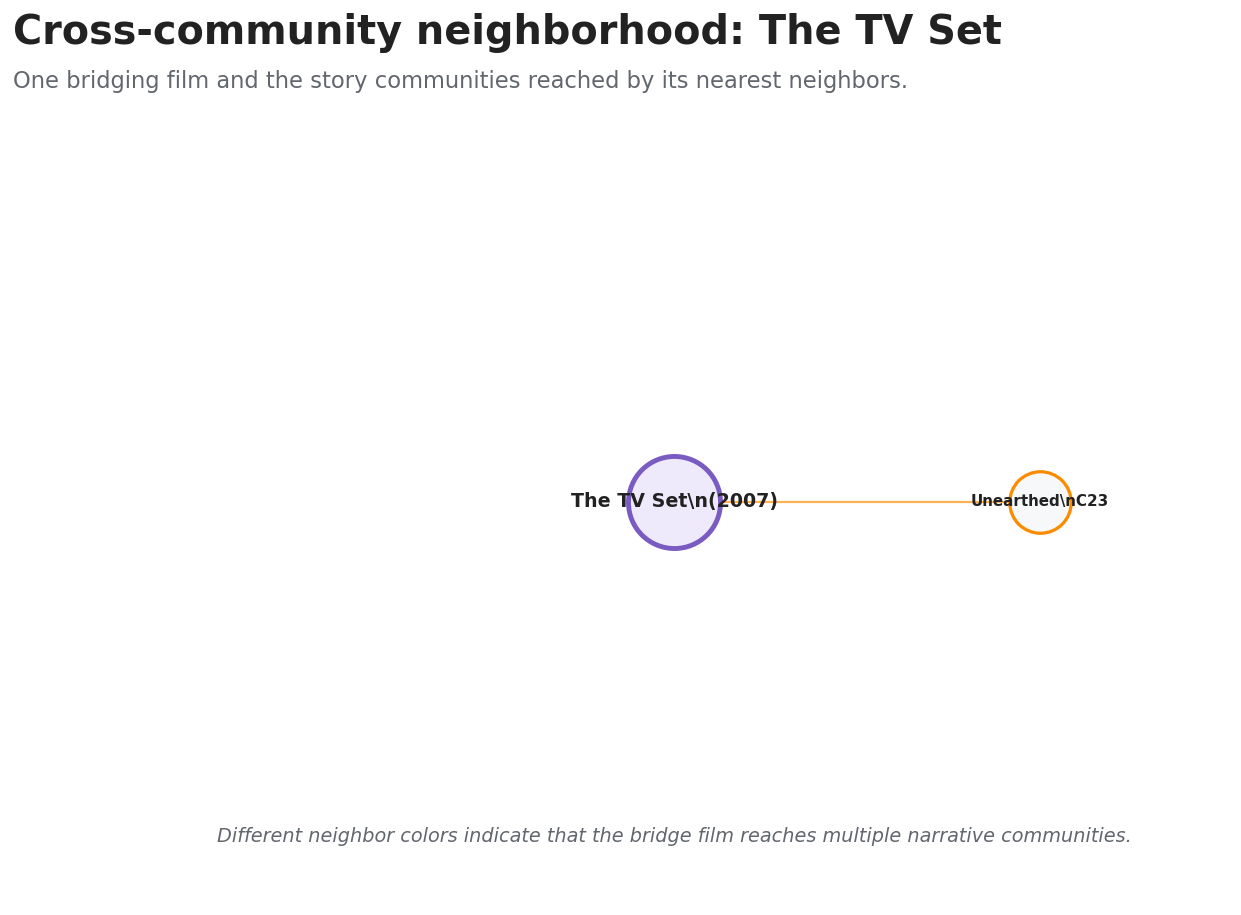

In [10]:

selected = bridge_ranked.head(3).copy()

for _, r in selected.iterrows():
    cid = int(r["community_id"]) if pd.notna(r.get("community_id")) else 0
    color = community_color(cid)
    node_id = r[node_id_col]
    title = clean_title(r.get("title", r.get(title_col, "")))
    year = r.get("release_year", "—")
    try:
        if pd.notna(year):
            year = int(year)
    except Exception:
        pass

    neigh = get_neighbors(node_id, top_n=10)
    if len(neigh) == 0:
        continue

    safe_title = re.sub(r"[^A-Za-z0-9]+", "_", title)[:25]
    save_table(neigh, f"06_cross_community_neighborhood_C{cid:02d}_{safe_title}.csv")

    fig, ax = plt.subplots(figsize=(11, 8))
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    title_block(
        fig,
        f"Cross-community neighborhood: {title}",
        "One bridging film and the story communities reached by its nearest neighbors.",
        x=0.05,
        y=0.965
    )

    center = (0.50, 0.50)
    ax.scatter(center[0], center[1], s=2600, color=COL["light_purple"], edgecolor=COL["purple"], linewidth=2.7, zorder=5)
    ax.text(center[0], center[1], wrap_text(f"{title}\\n({year})", 18), ha="center", va="center", fontsize=10.5, fontweight="bold", zorder=6)

    n = min(len(neigh), 10)
    angles = np.linspace(0, 2*np.pi, n, endpoint=False)
    radius = 0.33
    weights = neigh["edge_weight"].fillna(neigh["edge_weight"].median()).values[:n]
    wmin, wmax = np.nanmin(weights), np.nanmax(weights)

    for angle, (_, nr), w in zip(angles, neigh.head(n).iterrows(), weights):
        x = center[0] + radius * np.cos(angle)
        y = center[1] + radius * np.sin(angle)
        ncid = nr["neighbor_community"]
        ncolor = community_color(ncid)
        lw = 1.2 + 4.2 * ((w - wmin) / (wmax - wmin + 1e-9))
        ax.plot([center[0], x], [center[1], y], color=ncolor, alpha=0.68, lw=lw, zorder=1)
        ax.scatter(x, y, s=1160, color=COL["panel"], edgecolor=ncolor, linewidth=1.8, zorder=3)
        ax.text(x, y, wrap_text(f"{nr['neighbor_title']}\\nC{nr['neighbor_community']}", 18), ha="center", va="center", fontsize=8.4, fontweight="bold", zorder=4)

    ax.text(
        0.50, 0.075,
        "Different neighbor colors indicate that the bridge film reaches multiple narrative communities.",
        ha="center",
        fontsize=10.7,
        color=COL["muted"],
        style="italic"
    )

    save_fig(fig, f"06_bridge_local_cross_community_neighborhood_C{cid:02d}_{safe_title}.png")
    plt.show()


## 10. Figure 7 — Bridge versus typicality selected map

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/tables/07_bridge_vs_centrality_selected_map_data.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/07_bridge_vs_centrality_selected_map.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/07_bridge_vs_centrality_selected_map.svg


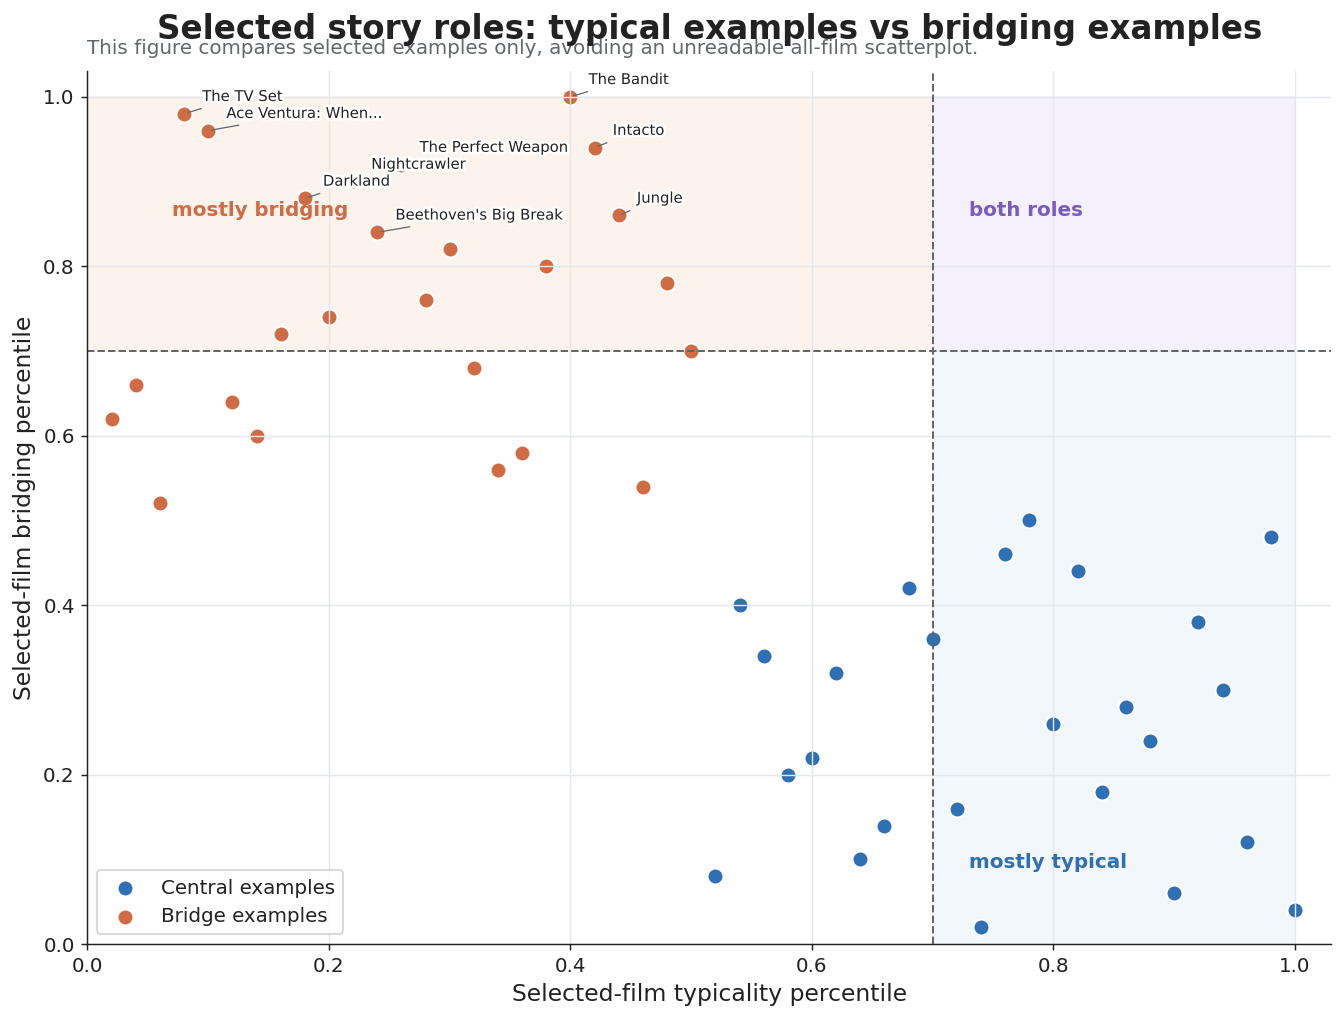

In [18]:
selected_bridge = bridge_source.sort_values("bridge_score", ascending=False).head(25).copy()

central_source = None
for df in [top_visible_central, top_weighted_degree_visible]:
    if df is not None and len(df):
        central_source = df.copy()
        break

if central_source is not None:
    if node_id_col not in central_source.columns:
        ids = []
        for _, rr in central_source.iterrows():
            hit = find_node_by_title(clean_title(rr.get("title", "")))
            ids.append(hit[node_id_col] if hit is not None else np.nan)
        central_source[node_id_col] = ids
    central_source = central_source.dropna(subset=[node_id_col]).copy()
    central_source = central_source.merge(
        bridge_nodes[[node_id_col, "bridge_score", "weighted_degree_from_edges"]],
        on=node_id_col,
        how="left",
        suffixes=("", "_node")
    )
    if "typicality_score" not in central_source.columns:
        if "weighted_degree" in central_source.columns:
            central_source["typicality_score"] = central_source["weighted_degree"]
        else:
            central_source["typicality_score"] = central_source["weighted_degree_from_edges"]
    selected_central = central_source.sort_values("typicality_score", ascending=False).head(25).copy()
else:
    selected_central = bridge_nodes.sort_values("weighted_degree_from_edges", ascending=False).head(25).copy()
    selected_central["typicality_score"] = selected_central["weighted_degree_from_edges"]

selected_bridge["role"] = "Bridge examples"
selected_central["role"] = "Central examples"

# Reset indices to ensure uniqueness before concatenation
selected_bridge_reset = selected_bridge.reset_index(drop=True)
selected_central_reset = selected_central.reset_index(drop=True)

# Get common columns and ensure 'role' is included uniquely
common_columns_for_plot = list(set(selected_bridge_reset.columns) & set(selected_central_reset.columns))
if "role" not in common_columns_for_plot:
    common_columns_for_plot.append("role")

plot = pd.concat([
    selected_bridge_reset[common_columns_for_plot],
    selected_central_reset[common_columns_for_plot]
], ignore_index=True).drop_duplicates(subset=[node_id_col, "role"])

# Ensure columns
if "bridge_score" not in plot.columns:
    plot["bridge_score"] = np.nan
if "typicality_score" not in plot.columns:
    if "weighted_degree_from_edges" in plot.columns:
        plot["typicality_score"] = plot["weighted_degree_from_edges"]
    else:
        plot["typicality_score"] = np.nan

# Percentile within selected plotted points for readability
plot["bridge_plot_pct"] = plot["bridge_score"].rank(pct=True)
plot["typicality_plot_pct"] = plot["typicality_score"].rank(pct=True)

save_table(plot, "07_bridge_vs_centrality_selected_map_data.csv")

fig, ax = plt.subplots(figsize=(10.5, 8))
ax.add_patch(patches.Rectangle((0.70, 0.00), 0.30, 0.70, color=COL["light_blue"], alpha=0.55, zorder=0))
ax.add_patch(patches.Rectangle((0.00, 0.70), 0.70, 0.30, color=COL["light_orange"], alpha=0.55, zorder=0))
ax.add_patch(patches.Rectangle((0.70, 0.70), 0.30, 0.30, color=COL["light_purple"], alpha=0.65, zorder=0))

ax.axvline(0.70, color=COL["muted"], ls="--", lw=1.1)
ax.axhline(0.70, color=COL["muted"], ls="--", lw=1.1)

for role, color in [("Central examples", COL["blue"]), ("Bridge examples", COL["orange"])]:
    sub = plot[plot["role"] == role]
    ax.scatter(sub["typicality_plot_pct"], sub["bridge_plot_pct"], s=78, color=color, edgecolor="white", linewidth=1.1, label=role)

# label top bridge points
label_df = plot.sort_values("bridge_plot_pct", ascending=False).head(9)
for _, rr in label_df.iterrows():
    title = clean_title(rr.get("title", rr.get(title_col, "")))
    ax.annotate(
        shorten(title, 22),
        xy=(rr["typicality_plot_pct"], rr["bridge_plot_pct"]),
        xytext=(rr["typicality_plot_pct"] + 0.015, rr["bridge_plot_pct"] + 0.015),
        fontsize=8.2,
        arrowprops=dict(arrowstyle="-", color=COL["muted"], lw=0.7),
        path_effects=[pe.withStroke(linewidth=3, foreground="white")]
    )

ax.text(0.73, 0.09, "mostly typical", fontsize=11, fontweight="bold", color=COL["blue"])
ax.text(0.07, 0.86, "mostly bridging", fontsize=11, fontweight="bold", color=COL["orange"])
ax.text(0.73, 0.86, "both roles", fontsize=11, fontweight="bold", color=COL["purple"])

ax.set_xlim(0, 1.03)
ax.set_ylim(0, 1.03)
ax.set_xlabel("Selected-film typicality percentile")
ax.set_ylabel("Selected-film bridging percentile")
ax.set_title("Selected story roles: typical examples vs bridging examples", pad=18)
ax.text(
    0, 1.02,
    "This figure compares selected examples only, avoiding an unreadable all-film scatterplot.",
    transform=ax.transAxes,
    fontsize=11,
    color=COL["muted"]
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=COL["grid"])
ax.legend(loc="lower left")

plt.tight_layout()
save_fig(fig, "07_bridge_vs_centrality_selected_map.png")
plt.show()

## 11. Figure 8 — Bridging interpretation summary

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/08_bridging_interpretation_summary.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/figures/08_bridging_interpretation_summary.svg


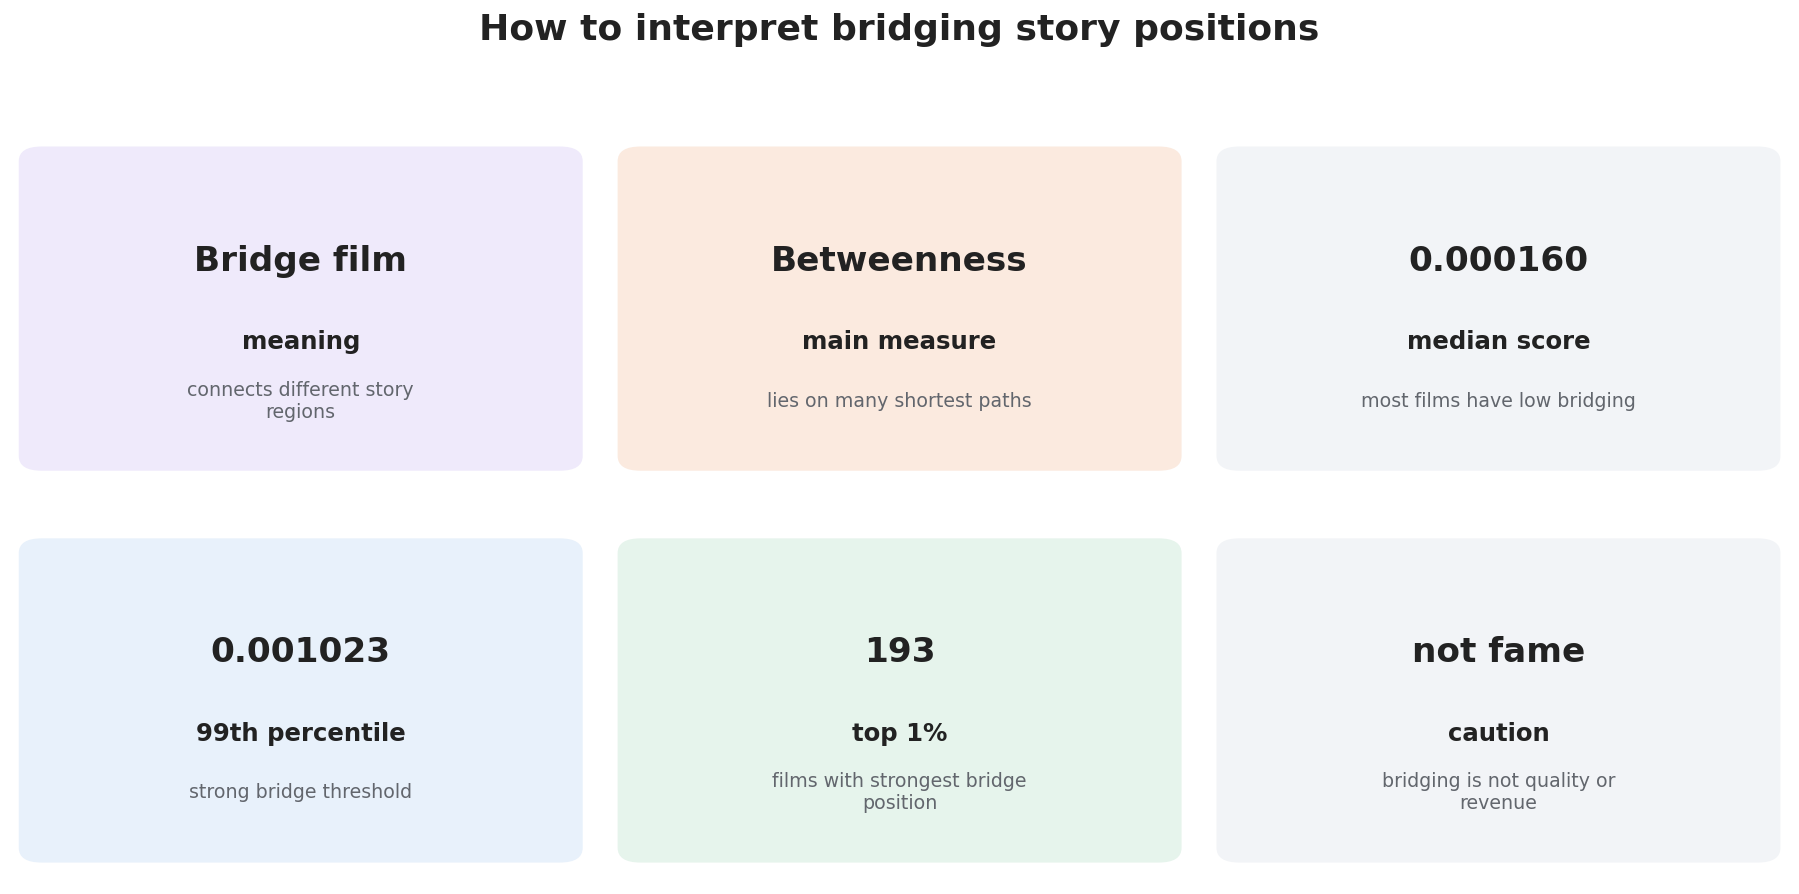

In [15]:

if "bridge_score" in bridge_nodes.columns:
    x = bridge_nodes["bridge_score"].dropna()
    top_1_pct = (bridge_nodes["bridge_percentile"] >= 0.99).sum() if "bridge_percentile" in bridge_nodes.columns else int(len(x) * .01)
    median_score = x.median()
    p99_score = x.quantile(.99)
    max_score = x.max()
else:
    top_1_pct = np.nan
    median_score = np.nan
    p99_score = np.nan
    max_score = np.nan

cards = [
    ("Bridge film", "meaning", "connects different story regions", COL["light_purple"]),
    ("Betweenness", "main measure", "lies on many shortest paths", COL["light_orange"]),
    (fmt_float(median_score, 6), "median score", "most films have low bridging", COL["light_gray"]),
    (fmt_float(p99_score, 6), "99th percentile", "strong bridge threshold", COL["light_blue"]),
    (fmt_int(top_1_pct), "top 1%", "films with strongest bridge position", COL["light_green"]),
    ("not fame", "caution", "bridging is not quality or revenue", COL["light_gray"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (value, title, subtitle, bg) in zip(axes, cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=19, fontweight="bold")
    ax.text(0.5, 0.40, title, ha="center", va="center", fontsize=13.5, fontweight="bold")
    ax.text(0.5, 0.24, wrap_text(subtitle, 28), ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("How to interpret bridging story positions", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "08_bridging_interpretation_summary.png")
plt.show()


## 12. Export interpretation note

In [16]:

note = """
Brick 6 — Bridging story positions interpretation note

This section should appear after central story positions.

Main message:
A bridging film is a film that lies between different narrative regions in the plot-similarity network. In this thesis, bridging is interpreted as narrative brokerage or cross-community story position, not as fame, quality, revenue, or star power.

Recommended main thesis figures:
1. 01_bridging_as_narrative_brokerage.png
2. 02_betweenness_explainer.png
3. 04_bridging_films_ranked_table.png
4. Selected 05_bridge_profile_CXX.png profile sheets
5. Selected 06_bridge_local_cross_community_neighborhood_CXX.png local neighborhoods

Recommended appendix/supporting figures:
1. 03_betweenness_distribution.png
2. 07_bridge_vs_centrality_selected_map.png
3. 08_bridging_interpretation_summary.png

Important wording:
Betweenness centrality is used because it captures how often a film lies between other films in the network path structure. In narrative terms, this can indicate films whose plot descriptions connect otherwise separate story neighborhoods.
""".strip()

write_text(note, "brick_06_interpretation_note.txt")
print(note)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions/text/brick_06_interpretation_note.txt
Brick 6 — Bridging story positions interpretation note

This section should appear after central story positions.

Main message:
A bridging film is a film that lies between different narrative regions in the plot-similarity network. In this thesis, bridging is interpreted as narrative brokerage or cross-community story position, not as fame, quality, revenue, or star power.

Recommended main thesis figures:
1. 01_bridging_as_narrative_brokerage.png
2. 02_betweenness_explainer.png
3. 04_bridging_films_ranked_table.png
4. Selected 05_bridge_profile_CXX.png profile sheets
5. Selected 06_bridge_local_cross_community_neighborhood_CXX.png local neighborhoods

Recommended appendix/supporting figures:
1. 03_betweenness_distribution.png
2. 07_bridge_vs_centrality_selected_map.png
3. 08_bridging_interpretation_summary.png

Important wording:
Betweenness centr

## 13. Output check

In [17]:

print("Figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)

print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)

print("\nText:")
for p in sorted(TEXT_DIR.glob("*.txt")):
    print("-", p.name)


Figures:
- 01_bridging_as_narrative_brokerage.png
- 02_betweenness_explainer.png
- 03_betweenness_distribution.png
- 04_bridging_films_ranked_table.png
- 05_bridge_profile_C01_Nightcrawler.png
- 05_bridge_profile_C06_The_TV_Set.png
- 05_bridge_profile_C10_Ace_Ventura_When_Nature_C.png
- 05_bridge_profile_C10_The_Perfect_Weapon.png
- 05_bridge_profile_C22_The_Bandit.png
- 05_bridge_profile_C23_Intacto.png
- 06_bridge_local_cross_community_neighborhood_C06_The_TV_Set.png
- 08_bridging_interpretation_summary.png

Tables:
- 00_bridge_node_diagnostics.csv
- 00_bridge_source_for_figures.csv
- 03_betweenness_distribution_summary.csv
- 04_bridging_films_ranked_table.csv
- 06_cross_community_neighborhood_C06_The_TV_Set.csv

Text:
- brick_06_interpretation_note.txt
